# MNIST Digit Classifier (PyTorch)

Feed-forward multi-layer perceptron, following the 3b1b ML Series notes:
784 input neurons, two hidden layers of 16, 10 output neurons, squared-error cost, and stochastic gradient descent with backprop.

In [1]:
import torch  # core tensor library
import torch.nn as nn  # neural network layers
from torch.utils.data import DataLoader  # mini-batch loader
from torchvision import datasets, transforms  # MNIST dataset and image transforms
import matplotlib.pyplot as plt  # plotting

## Setup

In [2]:
torch.manual_seed(0)  # reproducible random weights and shuffling
device = "cuda" if torch.cuda.is_available() else "cpu"  # use GPU if available
batch_size = 64  # images per mini-batch
learning_rate = 1.0  # step size for gradient descent
epochs = 10  # full passes over the training set

## Data

Each 28x28 image becomes 784 greyscale activations between 0 (black) and 1 (white).

In [3]:
transform = transforms.ToTensor()  # converts image to tensor with values in [0, 1]
train_set = datasets.MNIST(root="data", train=True, download=True, transform=transform)  # 60k training images
test_set = datasets.MNIST(root="data", train=False, download=True, transform=transform)  # 10k test images
train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)  # shuffle then split into batches
test_loader = DataLoader(test_set, batch_size=1000)  # larger batches for evaluation

100.0%
100.0%
100.0%
100.0%


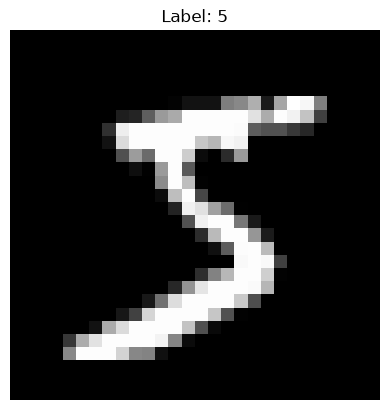

In [5]:
image, label = train_set[0]  # grab one example
plt.imshow(image.squeeze(), cmap="gray")  # show the 28x28 image
plt.title(f"Label: {label}")  # expected digit
plt.axis("off")  # hide axes
plt.show()  # render

## Network

Each layer computes `f(Wa + b)`: weighted sum of the previous activations plus a bias, squashed by an activation function.
ReLU is used for the hidden layers and sigmoid for the output so every output neuron sits between 0 and 1.

In [6]:
class DigitClassifier(nn.Module):  # multi-layer perceptron
    def __init__(self):
        super().__init__()  # initialize nn.Module internals
        self.flatten = nn.Flatten()  # 28x28 image -> 784 vector
        self.hidden1 = nn.Linear(784, 16)  # input layer -> first hidden layer (weights + biases)
        self.hidden2 = nn.Linear(16, 16)  # first hidden -> second hidden layer
        self.output = nn.Linear(16, 10)  # second hidden -> 10 output neurons, one per digit
        self.relu = nn.ReLU()  # hidden layer activation function
        self.sigmoid = nn.Sigmoid()  # squashes outputs to (0, 1)

    def forward(self, x):  # feed-forward pass
        x = self.flatten(x)  # flatten pixels into input activations
        x = self.relu(self.hidden1(x))  # activations of hidden layer 1
        x = self.relu(self.hidden2(x))  # activations of hidden layer 2
        return self.sigmoid(self.output(x))  # output activations

model = DigitClassifier().to(device)  # create the network on the chosen device
print(model)  # show the architecture
print(sum(p.numel() for p in model.parameters()), "weights and biases")  # size of the column vector W

DigitClassifier(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (hidden1): Linear(in_features=784, out_features=16, bias=True)
  (hidden2): Linear(in_features=16, out_features=16, bias=True)
  (output): Linear(in_features=16, out_features=10, bias=True)
  (relu): ReLU()
  (sigmoid): Sigmoid()
)
13002 weights and biases


## Cost function and optimizer

Cost is the sum of squared differences between the output and the expected one-hot vector, averaged over the batch.
SGD steps the parameters along the negative gradient, which backprop computes.

In [7]:
def cost_fn(output, labels):  # squared-error cost
    expected = nn.functional.one_hot(labels, num_classes=10).float()  # e.g. 3 -> [0,0,0,1,0,0,0,0,0,0]
    return ((output - expected) ** 2).sum(dim=1).mean()  # sum per example, mean over batch

optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)  # stochastic gradient descent

## Training

In [8]:
def evaluate():  # accuracy on the test set
    model.eval()  # evaluation mode
    correct = 0  # running count of correct predictions
    with torch.no_grad():  # no gradients needed
        images: torch.Tensor
        labels: torch.Tensor
        for images, labels in test_loader:  # loop over test batches
            images, labels = images.to(device), labels.to(device)  # move to device
            preds = model(images).argmax(dim=1)  # brightest output neuron is the choice
            correct += (preds == labels).sum().item()  # count matches
    return correct / len(test_set)  # fraction correct

In [16]:
history = []  # average cost per epoch
for epoch in range(epochs):  # repeat over the dataset
    model.train()  # training mode
    total_cost = 0.0  # running cost for this epoch
    for images, labels in train_loader:  # one mini-batch at a time
        images, labels = images.to(device), labels.to(device)  # move to device
        output = model(images)  # forward pass
        cost = cost_fn(output, labels)  # how wrong the network is
        optimizer.zero_grad()  # clear old gradients
        cost.backward()  # backpropagation computes the gradient
        optimizer.step()  # nudge W along the negative gradient
        total_cost += cost.item()  # accumulate cost
    avg_cost = total_cost / len(train_loader)  # mean cost over batches
    history.append(avg_cost)  # record for plotting
    print(f"Epoch {epoch + 1}: cost {avg_cost:.4f}, test accuracy {evaluate():.2%}")  # progress

Epoch 1: cost 0.0807, test accuracy 94.80%
Epoch 2: cost 0.0796, test accuracy 94.07%
Epoch 3: cost 0.0810, test accuracy 91.47%
Epoch 4: cost 0.0784, test accuracy 94.83%
Epoch 5: cost 0.0785, test accuracy 94.62%
Epoch 6: cost 0.0783, test accuracy 94.33%
Epoch 7: cost 0.0790, test accuracy 94.58%
Epoch 8: cost 0.0792, test accuracy 94.67%
Epoch 9: cost 0.0776, test accuracy 94.61%
Epoch 10: cost 0.0780, test accuracy 94.55%


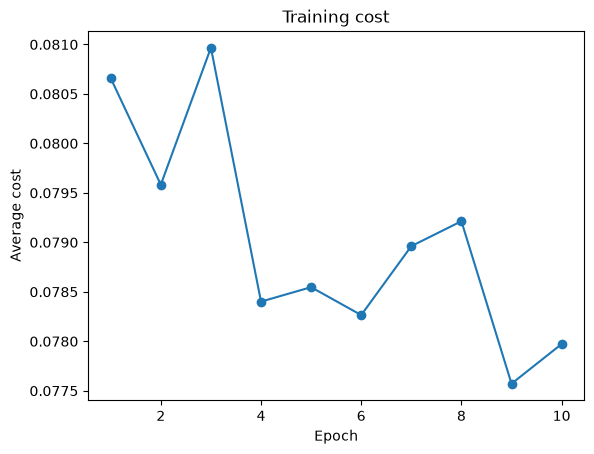

In [17]:
plt.plot(range(1, epochs + 1), history, marker="o")  # cost curve
plt.xlabel("Epoch")  # x label
plt.ylabel("Average cost")  # y label
plt.title("Training cost")  # title
plt.show()  # render

## Predictions

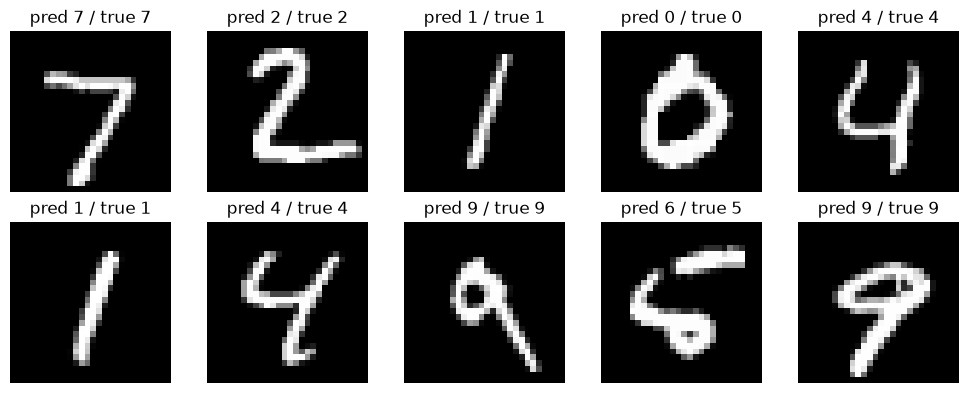

In [20]:
model.eval()  # evaluation mode
images, labels = next(iter(test_loader))  # one test batch
with torch.no_grad():  # no gradients needed
    preds = model(images.to(device)).argmax(dim=1).cpu()  # predicted digits

fig, axes = plt.subplots(2, 5, figsize=(10, 4))  # grid of 10 images
for i, ax in enumerate(axes.flat):  # fill each slot
    ax.imshow(images[i].squeeze(), cmap="gray")  # show image
    ax.set_title(f"pred {preds[i].item()} / true {labels[i].item()}")  # prediction vs label
    ax.axis("off")  # hide axes
plt.tight_layout()  # tidy spacing
plt.show()  # render

## Static noise

From the notes: given a non-digit image, the network still answers confidently instead of being uncertain.

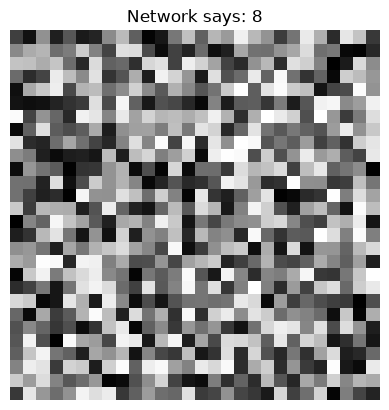

[0.05, 0.0, 0.05, 0.13, 0.0, 0.0, 0.0, 0.0, 0.68, 0.0]


In [12]:
noise = torch.rand(1, 1, 28, 28)  # random static image
with torch.no_grad():  # no gradients needed
    out = model(noise.to(device)).cpu().squeeze()  # output activations
plt.imshow(noise.squeeze(), cmap="gray")  # show the noise
plt.title(f"Network says: {out.argmax().item()}")  # its confident guess
plt.axis("off")  # hide axes
plt.show()  # render
print([round(v, 2) for v in out.tolist()])  # all 10 output activations

## Visualize first-layer weights

As the notes say, the learned weights look non-intuitive.

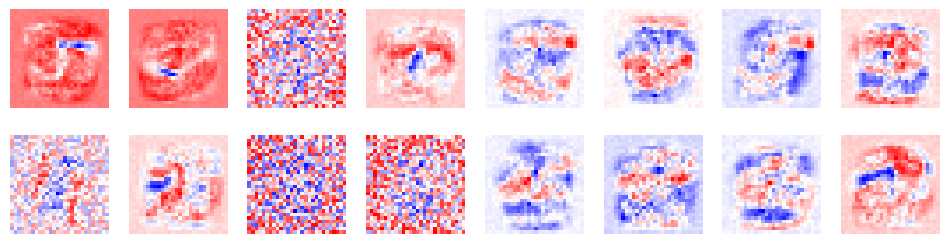

In [13]:
weights = model.hidden1.weight.detach().cpu()  # 16 x 784 weight matrix
fig, axes = plt.subplots(2, 8, figsize=(12, 3))  # one tile per hidden neuron
for i, ax in enumerate(axes.flat):  # fill each tile
    ax.imshow(weights[i].view(28, 28), cmap="bwr")  # reshape weights to image (blue negative, red positive)
    ax.axis("off")  # hide axes
plt.show()  # render